In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('https://github.com/Indhumathi-13/Python-/raw/refs/heads/main/taxi_trips_dataset.csv')
df.head()

,trip_id,pickup_datetime,dropoff_datetime,pickup_borough,dropoff_borough,passenger_count,trip_distance_km,trip_duration_min,traffic_level,weather,rate_code,payment_method,fare_amount,tip_amount,tolls_amount,total_amount,pickup_hour,day_of_week
0,TAXI100001,3/26/2025 16:38,3/26/2025 16:57,Queens,Manhattan,4,4.81,19,Medium,Clear,Standard,Cash,14.28,0.00,0.0,14.28,16,Wednesday
1,TAXI100002,1/11/2025 23:15,1/11/2025 23:35,Brooklyn,Manhattan,1,4.14,20,High,Rain,Standard,Cash,14.15,2.18,0.0,16.33,23,Saturday
2,TAXI100003,1/1/2025 14:20,1/1/2025 14:40,Manhattan,Manhattan,1,3.42,20,Medium,Clear,Standard,Credit Card,12.47,0.00,0.0,12.47,14,Wednesday
3,TAXI100004,3/14/2025 0:14,3/14/2025 0:26,Bronx,Brooklyn,3,2.69,12,Low,Clear,Airport,Cash,9.25,1.16,0.0,10.41,0,Friday
4,TAXI100005,3/30/2025 23:06,3/30/2025 23:25,Queens,Brooklyn,1,4.99,19,High,Snow,Standard,Credit Card,15.06,1.46,0.0,16.52,23,Sunday


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   trip_id            1000 non-null   str    
 1   pickup_datetime    1000 non-null   str    
 2   dropoff_datetime   1000 non-null   str    
 3   pickup_borough     1000 non-null   str    
 4   dropoff_borough    1000 non-null   str    
 5   passenger_count    1000 non-null   int64  
 6   trip_distance_km   1000 non-null   float64
 7   trip_duration_min  1000 non-null   int64  
 8   traffic_level      999 non-null    str    
 9   weather            1000 non-null   str    
 10  rate_code          1000 non-null   str    
 11  payment_method     1000 non-null   str    
 12  fare_amount        999 non-null    float64
 13  tip_amount         1000 non-null   float64
 14  tolls_amount       1000 non-null   float64
 15  total_amount       1000 non-null   float64
 16  pickup_hour        1000 non-null   i

In [18]:
df.columns

Index(['trip_id', 'pickup_datetime', 'dropoff_datetime', 'pickup_borough',
       'dropoff_borough', 'passenger_count', 'trip_distance_km',
       'trip_duration_min', 'traffic_level', 'weather', 'rate_code',
       'payment_method', 'fare_amount', 'tip_amount', 'tolls_amount',
       'total_amount', 'pickup_hour', 'day_of_week'],
      dtype='str')

In [19]:
df.isnull().sum()

trip_id              0
pickup_datetime      0
dropoff_datetime     0
pickup_borough       0
dropoff_borough      0
passenger_count      0
trip_distance_km     0
trip_duration_min    0
traffic_level        1
weather              0
rate_code            0
payment_method       0
fare_amount          1
tip_amount           0
tolls_amount         0
total_amount         0
pickup_hour          0
day_of_week          0
dtype: int64

In [20]:
df.isnull().sum()[df.isnull().sum()>0]

traffic_level    1
fare_amount      1
dtype: int64

In [21]:
num_cols=df.select_dtypes(include=['int64','float64']).columns

In [26]:
cat_col=df.select_dtypes(include=['object','category']).columns

C:\Users\Aravindan\AppData\Local\Temp\ipykernel_12676\2662714662.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col=df.select_dtypes(include=['object','category']).columns


In [25]:
for col in num_cols:
    df[col]=df[col].fillna(df[col].median())

In [28]:
for col in cat_col:
    df[col]=df[col].fillna(df[col].mode())

In [30]:
df=df.dropna(subset=['traffic_level','fare_amount'])

In [31]:
df.isnull().sum()

trip_id              0
pickup_datetime      0
dropoff_datetime     0
pickup_borough       0
dropoff_borough      0
passenger_count      0
trip_distance_km     0
trip_duration_min    0
traffic_level        0
weather              0
rate_code            0
payment_method       0
fare_amount          0
tip_amount           0
tolls_amount         0
total_amount         0
pickup_hour          0
day_of_week          0
dtype: int64

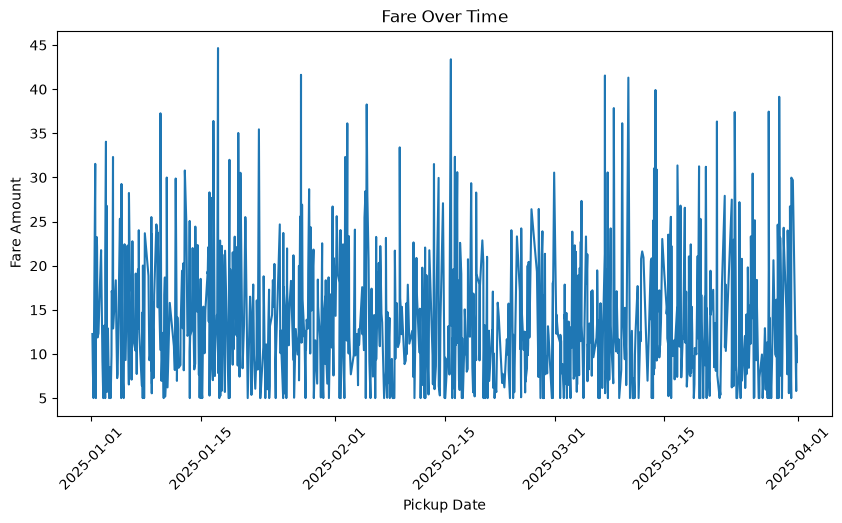

In [35]:
df['pickup_datetime']=pd.to_datetime(df['pickup_datetime'])
df=df.sort_values('pickup_datetime')
plt.figure(figsize=(10,5))
plt.plot(df['pickup_datetime'],df['fare_amount'])
plt.xlabel('Pickup Date')
plt.ylabel('Fare Amount')
plt.title('Fare Over Time')
plt.xticks(rotation=45)
plt.show()

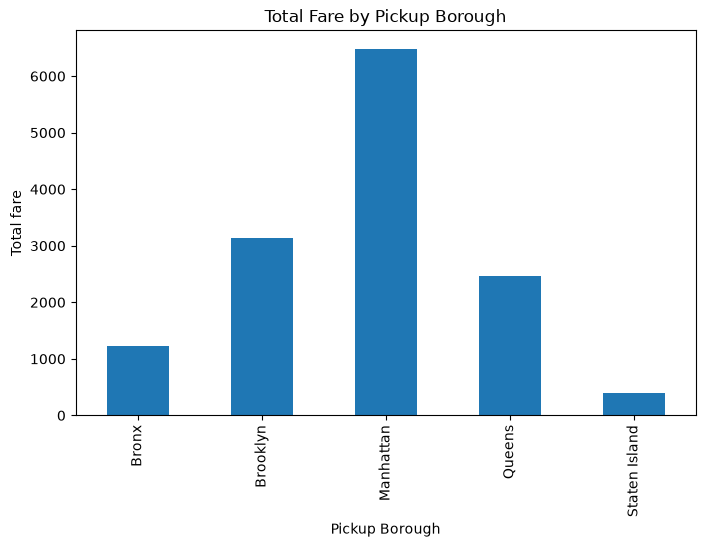

In [36]:
borough_fare=df.groupby('pickup_borough')['fare_amount'].sum()
borough_fare.plot(kind='bar',figsize=(8,5))
plt.xlabel('Pickup Borough')
plt.ylabel('Total fare')
plt.title('Total Fare by Pickup Borough')
plt.show()


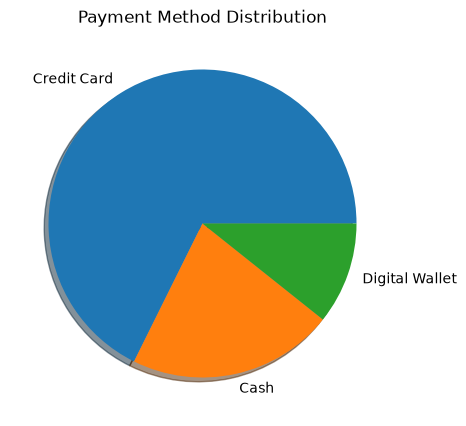

In [77]:
payment_counts=df['payment_method'].value_counts()
plt.figure(figsize=(5,5))
plt.pie(payment_counts,labels=payment_counts.index,shadow=True)
plt.title('Payment Method Distribution')
plt.show()

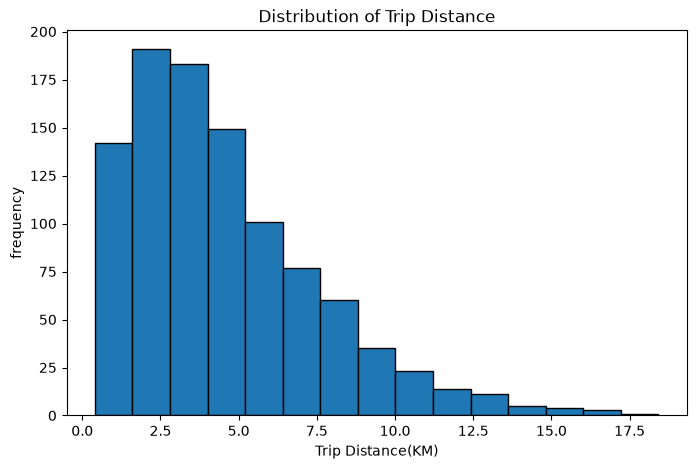

In [50]:
plt.figure(figsize=(8,5))
plt.hist(df['trip_distance_km'],bins=15, edgecolor='black')
plt.xlabel('Trip Distance(KM)')
plt.ylabel("frequency")
plt.title('Distribution of Trip Distance')
plt.show()

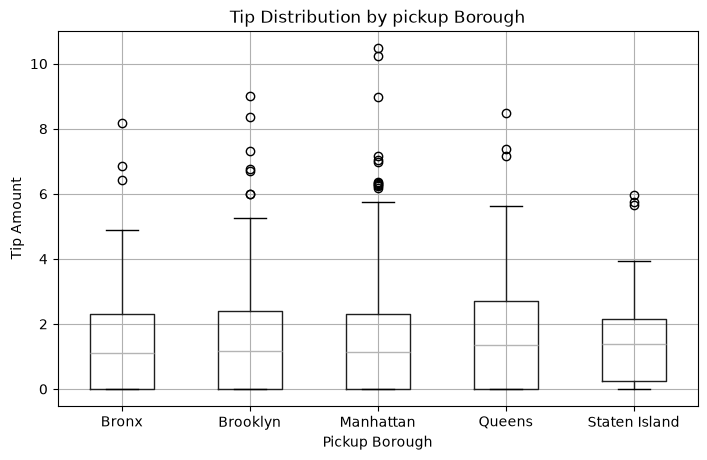

In [57]:
df.boxplot(column='tip_amount',by='pickup_borough',figsize=(8,5))
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.title('Tip Distribution by pickup Borough')
plt.suptitle('')
plt.show()

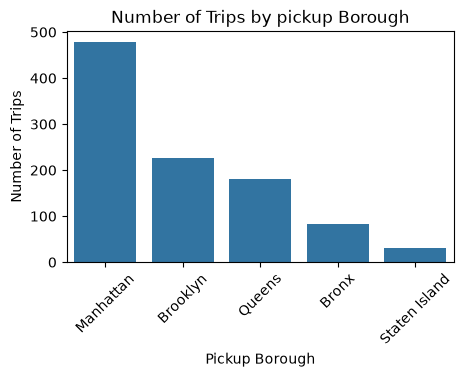

In [80]:
plt.figure(figsize=(5,3))
sns.countplot(data=df, x='pickup_borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.title('Number of Trips by pickup Borough')
plt.xticks(rotation=45)
plt.show()

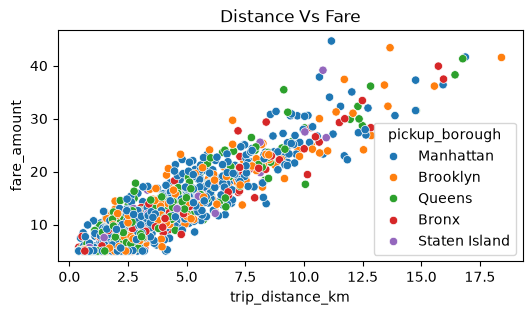

In [81]:
plt.figure(figsize=(6,3))
sns.scatterplot(data=df,x='trip_distance_km',y='fare_amount',hue='pickup_borough')
plt.title('Distance Vs Fare')
plt.xlabel('trip_distance_km')
plt.ylabel('fare_amount')
plt.show()

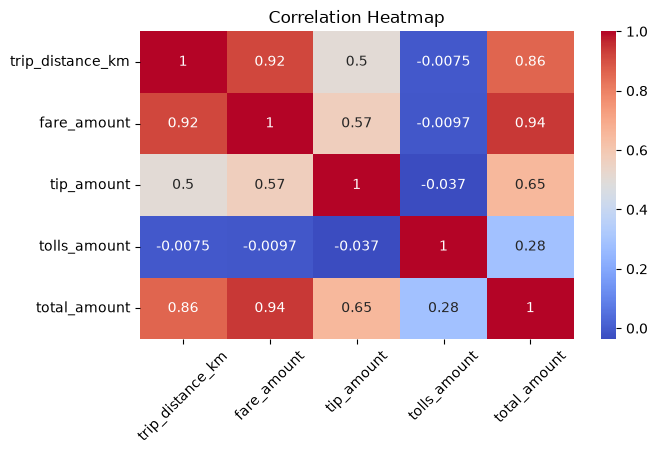

In [82]:
corr=df[['trip_distance_km','fare_amount','tip_amount','tolls_amount','total_amount']].corr()
plt.figure(figsize=(7,4))
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.xticks(rotation=45)
plt.show()

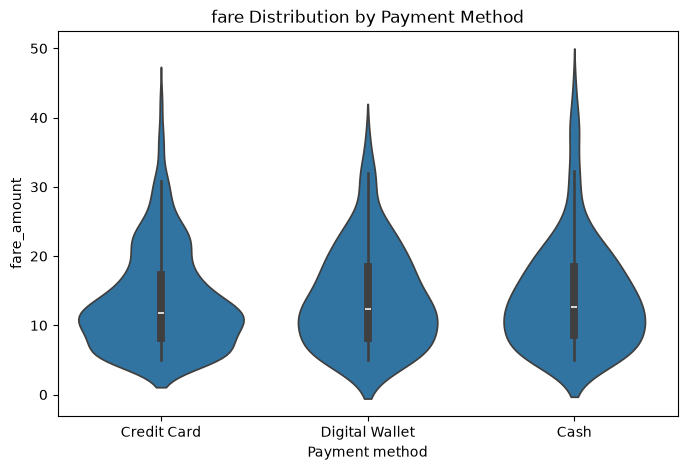

In [70]:
plt.figure(figsize=(8,5))
sns.violinplot(data=df,x='payment_method',y='fare_amount')
plt.xlabel('Payment method')
plt.ylabel('fare_amount')
plt.title('fare Distribution by Payment Method')
plt.show()

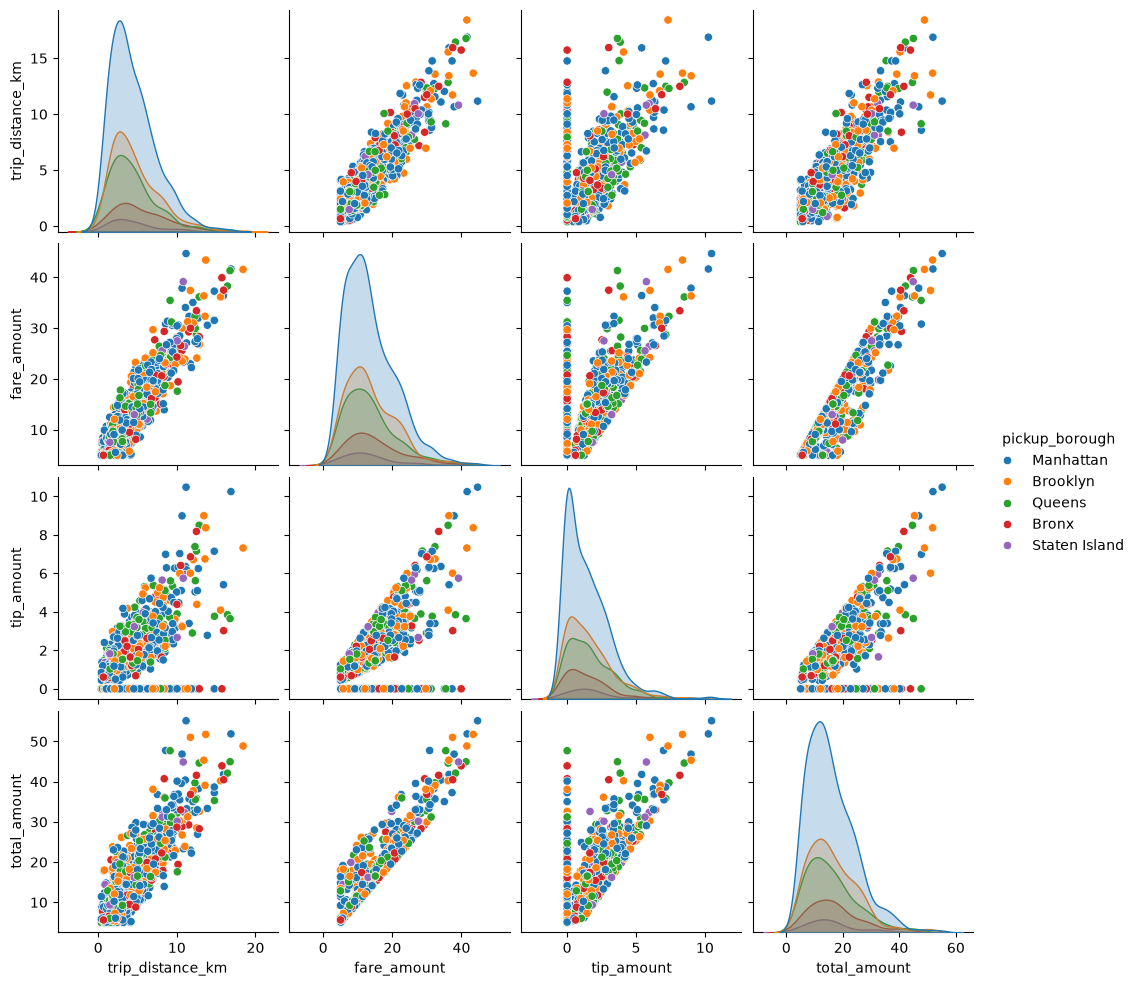

In [91]:
sns.pairplot(df,vars=['trip_distance_km','fare_amount','tip_amount','total_amount'],hue='pickup_borough')
plt.show()